# Capítulo 2 — O atraso é o principal motivo das notas ruins

Pergunta: **o atraso na entrega explica as notas baixas?**

Base: `order_reviews_all.csv` (1 linha por review), gerada em `score-initial-analisys.ipynb`.
Aqui só entram pedidos **entregues**. Um pedido é *atrasado* quando chegou depois da data estimada
(chegar no próprio dia previsto conta como no prazo).

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

from utils import AZUL, LARANJA, CINZA, TEXTO, TEXTO_2, NORDESTE
from utils import aplicar_estilo, subtitulo, fonte, salvar, carregar_base, apenas_entregues

aplicar_estilo()
base = carregar_base()
entregues = apenas_entregues(base)
print("reviews:", len(base), "| reviews de pedidos entregues:", len(entregues))

reviews: 99224 | reviews de pedidos entregues: 96359


## 2.1 Quanto menor a nota, maior a chance de o pedido ter atrasado

,qtd_reviews,porcentagem_atrasados
review_score,,
1,9409,36.6
2,2941,18.9
3,7962,8.8
4,18987,3.4
5,57060,1.9


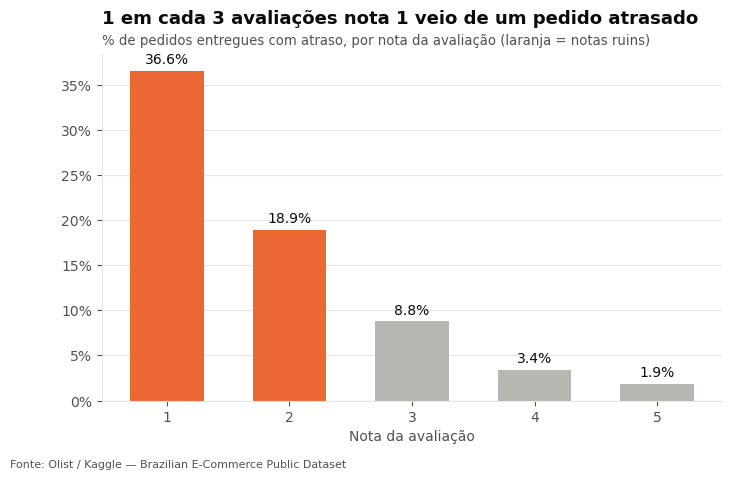

In [2]:
atraso_por_nota = (
    entregues.groupby("review_score")
    .agg(qtd_reviews=("review_id", "count"), porcentagem_atrasados=("entrega_atrasada", "mean"))
)
atraso_por_nota["porcentagem_atrasados"] *= 100
display(atraso_por_nota.round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
cores = [LARANJA if nota < 3 else CINZA for nota in atraso_por_nota.index]
barras = ax.bar(atraso_por_nota.index, atraso_por_nota["porcentagem_atrasados"], color=cores, width=0.6)
ax.bar_label(barras, labels=[f"{v:.1f}%" for v in atraso_por_nota["porcentagem_atrasados"]], padding=3, color=TEXTO)
ax.set_title("1 em cada 3 avaliações nota 1 veio de um pedido atrasado", pad=22)
subtitulo(ax, "% de pedidos entregues com atraso, por nota da avaliação (laranja = notas ruins)")
ax.set_xlabel("Nota da avaliação")
ax.set_xticks([1, 2, 3, 4, 5])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
fonte(fig)
salvar(fig, "01_atraso_por_nota")
plt.show()

## 2.2 A nota média cai quase pela metade quando o pedido atrasa

,qtd_reviews,nota_media,porcentagem_notas_ruins
entrega_atrasada,,,
No prazo,89949,4.29,9.28
Atrasado,6410,2.27,62.40


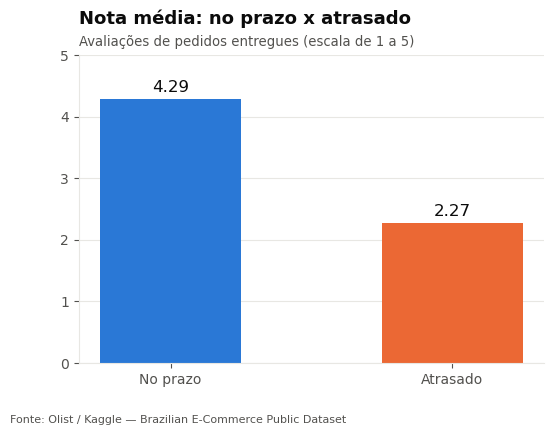

In [3]:
nota_media = (
    entregues.groupby("entrega_atrasada")
    .agg(qtd_reviews=("review_id", "count"), nota_media=("review_score", "mean"),
         porcentagem_notas_ruins=("nota_ruim", "mean"))
    .rename(index={False: "No prazo", True: "Atrasado"})
)
nota_media["porcentagem_notas_ruins"] *= 100
display(nota_media.round(2))

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(nota_media.index, nota_media["nota_media"], color=[AZUL, LARANJA], width=0.5)
ax.bar_label(barras, labels=[f"{v:.2f}" for v in nota_media["nota_media"]], padding=3, color=TEXTO, fontsize=12)
ax.set_title("Nota média: no prazo x atrasado", pad=22)
subtitulo(ax, "Avaliações de pedidos entregues (escala de 1 a 5)")
ax.set_ylim(0, 5)
ax.grid(axis="x", visible=False)
fonte(fig)
salvar(fig, "02_nota_media_prazo_vs_atraso")
plt.show()

## 2.3 Não é só atrasar ou não: a nota acompanha a folga em relação ao prazo

Separando os pedidos em faixas — de "chegou 3 semanas antes" até "atrasou mais de 2 semanas".

,qtd_reviews,nota_media
faixa_prazo,,
21+ dias\nantes,13494,4.29
14–20\nantes,28613,4.34
7–13\nantes,34073,4.30
3–6\nantes,9473,4.19
0–2\nantes,4296,4.11
1–3\natraso,1856,3.29
4–7\natraso,1756,2.10
8–14\natraso,1453,1.68
15+ dias\natraso,1345,1.72


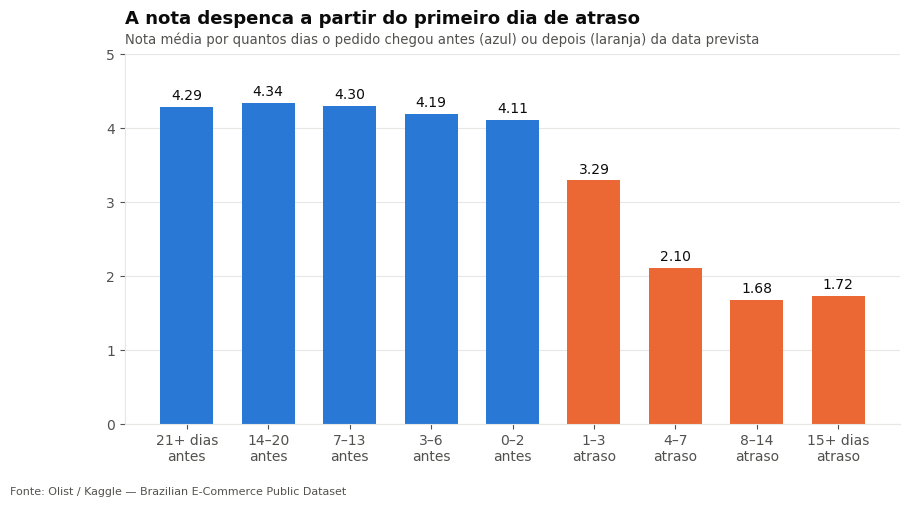

In [4]:
# delivery_delay_days: negativo = chegou antes do previsto, 0 = no dia, positivo = atrasou
limites = [-1000, -21, -14, -7, -3, 0, 3, 7, 14, 1000]
nomes = ["21+ dias\nantes", "14–20\nantes", "7–13\nantes", "3–6\nantes", "0–2\nantes",
         "1–3\natraso", "4–7\natraso", "8–14\natraso", "15+ dias\natraso"]
entregues["faixa_prazo"] = pd.cut(entregues["delivery_delay_days"], bins=limites, labels=nomes)

nota_por_faixa = entregues.groupby("faixa_prazo", observed=True).agg(
    qtd_reviews=("review_id", "count"), nota_media=("review_score", "mean"))
display(nota_por_faixa.round(2))

fig, ax = plt.subplots(figsize=(10, 4.8))
cores = [AZUL] * 5 + [LARANJA] * 4
barras = ax.bar(range(len(nota_por_faixa)), nota_por_faixa["nota_media"], color=cores, width=0.65)
ax.bar_label(barras, labels=[f"{v:.2f}" for v in nota_por_faixa["nota_media"]], padding=3, color=TEXTO)
ax.set_xticks(range(len(nota_por_faixa)), nota_por_faixa.index)
ax.set_title("A nota despenca a partir do primeiro dia de atraso", pad=22)
subtitulo(ax, "Nota média por quantos dias o pedido chegou antes (azul) ou depois (laranja) da data prevista")
ax.set_ylim(0, 5)
ax.grid(axis="x", visible=False)
fonte(fig)
salvar(fig, "03_nota_por_faixa_de_prazo")
plt.show()

## 2.4 O prazo prometido é bem maior que o prazo real

A Olist promete um prazo com bastante folga. Isso ajuda a explicar por que a maioria dos pedidos chega
"antes do prazo" — e por que, mesmo assim, chegar só no último dia já rende uma nota um pouco menor.

prazo prometido (mediana): 23 dias
prazo real (mediana):      10 dias
pedidos que chegaram 7+ dias antes do previsto: 79.1%


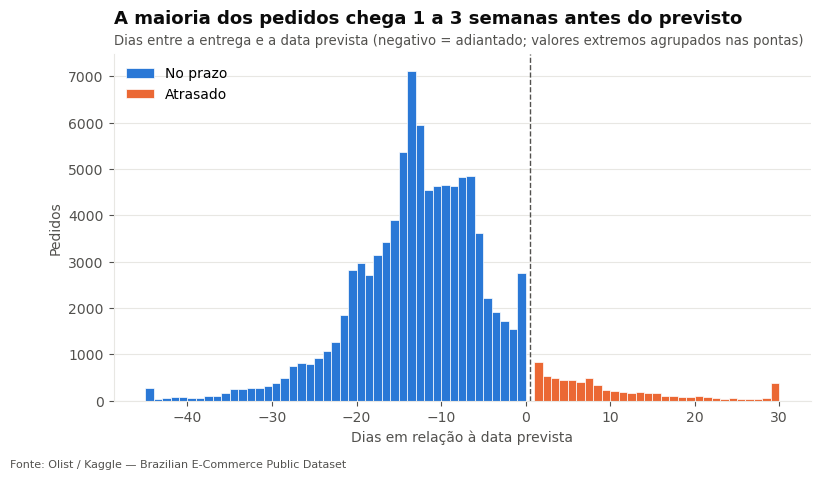

In [5]:
print(f"prazo prometido (mediana): {entregues['dias_prometidos'].median():.0f} dias")
print(f"prazo real (mediana):      {entregues['dias_entrega'].median():.0f} dias")
print(f"pedidos que chegaram 7+ dias antes do previsto: {(entregues['delivery_delay_days'] <= -7).mean() * 100:.1f}%")

fig, ax = plt.subplots(figsize=(9, 4.5))
folga = entregues["delivery_delay_days"].clip(-45, 30)
ax.hist(folga[folga <= 0], bins=range(-45, 1), color=AZUL, edgecolor="white", linewidth=0.5, label="No prazo")
ax.hist(folga[folga > 0], bins=range(1, 31), color=LARANJA, edgecolor="white", linewidth=0.5, label="Atrasado")
ax.axvline(0.5, color=TEXTO_2, linewidth=1, linestyle="--")
ax.set_title("A maioria dos pedidos chega 1 a 3 semanas antes do previsto", pad=22)
subtitulo(ax, "Dias entre a entrega e a data prevista (negativo = adiantado; valores extremos agrupados nas pontas)")
ax.set_xlabel("Dias em relação à data prevista")
ax.set_ylabel("Pedidos")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
fonte(fig)
salvar(fig, "04_folga_do_prazo")
plt.show()

## Conclusões do capítulo

- A nota média cai de **4,29** (no prazo) para **2,27** (atrasado).
- A % de pedidos atrasados cresce a cada nota mais baixa: **1,9%** nas notas 5 contra **36,6%** nas notas 1.
- A nota cai já nos **primeiros dias** de atraso (de 4,11 para 3,29) e continua caindo até cerca de 1 semana
  de atraso (1,68), quando estabiliza.
- O prazo prometido (mediana de 23 dias) é mais que o dobro do real (10 dias). Mesmo assim, chegar perto do
  limite do prazo já gera notas um pouco menores: a expectativa do cliente importa.